# Physical feedback scenarios already available in Cocoa

Gas cooling and outflows redistribute matter. A two-point correlation measures
pairs of density fluctuations; a three-point correlation also measures how
those fluctuations arrange into triangles. A model can therefore predict the
change in the power spectrum without predicting the change in the bispectrum.

This notebook follows the LSST Y1 and Roman feedback examples
(`projects/lsst_y1/EXAMPLE_EVALUATE3.ipynb` and
`projects/roman_real/EXAMPLE_EVALUATE3.ipynb`). It calls the same **bfmt
theory block**, compares all seven of its feedback scenarios, and propagates
their power responses into the DES Y3 $\xi_+$ and $\xi_-$ predictions. It also
calls both installed Burger2025 BACCO emulators, which predict a
power/bispectrum response pair from one feedback model. [EXAMPLE_JOINT_FEEDBACK](EXAMPLE_JOINT_FEEDBACK.ipynb)
applies that paired BACCO response to the joint rows.

The example points illustrate model choices; they are not feedback fits to
DES. The two-point predictions are the 400 rows of the project's Cobaya likelihood
at the evaluate point of `EXAMPLE_EVALUATE3.yaml`: only the nonlinear matter
power changes, while the intrinsic-alignment model and the covariance stay
fixed. The notebook produces no posterior, no
Fisher forecast and no exact paper reproduction.

1. Run the existing theory block at the DES cosmology
2. Compare the physical power responses
3. Propagate them into the two-point observables
4. Evaluate the installed paired BACCO models
5. Check extrapolation and save the numerical evidence

The functions of this study are defined in the notebook, in the cells that
start with "# Functions of this notebook"; every prediction comes from the
Cobaya likelihood with its `external_baryon_suppression` key on. The
[project acknowledgements](README.md#acknowledgements) credit the fastnc and
Y3 three-point calculations of Sugiyama and Gomes.

**Model and data.** The settings come from the two YAML files the run reads:

| Choice | Value |
| --- | --- |
| Configuration | `EXAMPLE_EVALUATE3.yaml` on `data/des_y3_xi3_sim.dataset`, which cuts the Map3 rows |
| Scenario catalog | `configs/feedback_scenarios.yaml`: three SP(k) relations, BCEmu, FLAMINGO, BACCO, BCemu2025 |
| Cosmology point | the yaml's evaluate point, with $\Omega_b=0.0463$ and $\sum m_\nu=0.06\,\mathrm{eV}$ |
| Data vector | 400 two-point rows; the figures show source pair (1,1) |
| Displayed scales | $0.05 \le k \le 8\,h/\mathrm{Mpc}$ at $z=0$ and $z=1$ |
| Outputs | figures in `chains/feedback_scenarios/`; arrays in `chains/feedback_scenarios.npz` |
| Threads | one worker each for BLAS, OpenMP and the JAX/TensorFlow emulator calls, on CPU |

Words used throughout:

- **DMO**, dark-matter-only: the gravity-only reference simulation or model; a
  feedback **response** is the ratio
  $R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$.
- The **bfmt theory block** is Cocoa's Cobaya component for baryonic feedback:
  a block that computes the power response other components request.
- An **emulator** is an interpolator trained on simulations, with a finite
  parameter and scale range; **SP(k)** instead maps a halo's baryon fraction
  to the power suppression.
- **BCM**, the baryonic correction model, moves matter around halos with five
  parameters; the Burger2025 BACCO pair predicts its power and bispectrum
  responses from the same parameters.
- **Cold matter** means cold dark matter plus baryons, without the massive
  neutrinos that total matter includes.
- **NLA**, the nonlinear-alignment model: the intrinsic-alignment model of
  `EXAMPLE_EVALUATE3.yaml`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
# BACCO uses JAX for these small preparation calls; no GPU is requested.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
from cobaya.yaml import yaml_load_file

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Run the existing theory block at the DES cosmology

A Cobaya theory block is a component that computes a requested quantity. Here
CAMB brings the expansion history and bfmt the response
$R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$, whose denominator is
the model's gravity-only reference. The likelihood requests $k$ in
$1/\mathrm{Mpc}$ as bfmt expects and reads the response at $hk$ for its
$h/\mathrm{Mpc}$ tables; CAMB, BiHalofit and bfmt run in the same Cobaya model.

The [scenario catalog](configs/feedback_scenarios.yaml) copies the LSST/Roman
feedback points: three SP(k) halo-baryon-fraction relations, BCEmu, FLAMINGO,
BACCO and BCemu2025. BACCO works at this DES point because $\Omega_b=0.0463$
sits inside its training box, while the LSST example's $\Omega_b=0.04$ fell
just below it. The models need not produce the same gas distribution or
suppression: they span modeling choices, not a common parameter prior.

The wrapper builds one Cobaya model per scenario, evaluates the gravity-only
model again afterward, and requires exactly its original two-point rows. BLAS and
OpenMP use one worker for this example. The notebook needs the installed
emulators and installs nothing itself; Cocoa's
documented keys (`external_modules/code/baryon_suppression/README.md`) set up
missing models. A notebook run recalculates the outputs rather than silently
reading a cache.

The next cell defines this notebook's functions. `run_scenarios` is the
scenario loop itself, and the run cell of this section calls only it; the
helpers above it build one scenario's Cobaya input (`scenario_information`),
evaluate it (`evaluate_scenario`), refuse missing emulator weights before
anything could download (`require_installed_theory_data`), and supply the
FLAMINGO tail test of section 5 (`held_tail_theory`) and the cold-matter
coordinates the paired check of section 4 reuses (`bacco_coordinates`).

In [3]:
# Functions of this notebook: run each feedback scenario through Cobaya.
# run_scenarios is the loop of section 1; the helpers above it build one
# scenario's Cobaya input (scenario_information), evaluate it
# (evaluate_scenario) and refuse missing emulator weights or a failed
# emulator call before they could pass as "no feedback".
import copy
import hashlib
import importlib.util
import json
import logging
from pathlib import Path

import numpy as np
import yaml

# COCOA = the Cocoa root (PROJECT is set by the setup cell).
COCOA = PROJECT.parents[1]

# Cobaya's name of the joint xi/Map3 likelihood, and the dataset whose mask
# keeps the 400 xi rows and cuts all 80 Map3 rows.
LIKELIHOOD = "des_3pcf.joint_shear"
XI_DATASET = "des_y3_xi3_sim.dataset"

# The catalog format tag guards against reading an unrelated YAML.
CATALOG_FORMAT = "des3pcf-bfmt-scenarios-v1"

# The FLAMINGO tail test holds R_P constant above this wavenumber [h/Mpc].
TAIL_PIVOT = 10.0


class TheoryMessages(logging.Handler):
    """Collect bfmt warnings so a failed emulator cannot pass as no feedback.

    Some bfmt error paths log a message and return R_P = 1 instead of
    raising an exception. run_scenarios attaches this handler to the bfmt
    logger for each evaluation and refuses the scenario when it collected
    any warning or error. The declared high-redshift continuation of bfmt
    (above_zmax) produces no warning and is accepted.
    """

    def __init__(self):
        """Start with an empty message list; the process logging is unchanged."""
        super().__init__(level=logging.WARNING)
        self.messages = []

    def emit(self, record):
        """Keep the fully formatted message produced by the theory block."""
        self.messages.append(record.getMessage())

def require_installed_theory_data(model_number):
    """Refuse missing emulator weights before a bfmt dependency can download.

    Several emulator packages fetch absent weight files from the internet
    when they are first constructed. A notebook must not do that silently,
    so the files those constructors read are checked first.

    Arguments:
      model_number = bfmt selector baryon_model, 1 through 5.
    Returns:
      nothing when every needed file is present.
    Raises:
      FileNotFoundError naming the first missing file; Cocoa's installation
      keys (external_modules/code/baryon_suppression/README.md) supply it.
    """
    from theory.bacco_bispectrum.emulator import installed_bacco_weights

    paths = []
    # baryon_model 2 = BCEmu and 5 = BCemu2025 read weight files from
    # the installed BCemu package; 4 = BACCO checks its own weight
    # folders below; the remaining selectors need no external files.
    if model_number in (2, 5):
        spec = importlib.util.find_spec(name="BCemu")
        if spec is None:
            raise FileNotFoundError("Install BCemu with Cocoa's installation keys.")
        base = Path(spec.origin).parent / "input_data"
        if model_number == 2:
            # BCEmu ships one emulator file per tabulated redshift (the
            # file names write 0.5 as "0p5").
            for redshift in ("0", "0p5", "1", "1p5", "2"):
                paths.append(base / f"kpls_emulator_z{redshift}_nComp3.pkl")
        else:
            paths.append(base / "BCemu2025_meta.json")
    if model_number == 4:
        installed_bacco_weights()
        spec = importlib.util.find_spec(name="baccoemu")
        base = Path(spec.origin).parent
        # bfmt also loads the ordinary BACCO power constructor, whose
        # directories trigger downloads when absent.
        for name in ("sigma8_emu_2.0.2", "cold_matter_linear_emu_1.0.2",
                     "total_matter_linear_emu_1.0.2", "no_wiggles_emu_1.0.2",
                     "nonlinear_emu_1.0.3"):
            paths.append(base / name)
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(f"Cocoa setup must supply {path} before evaluation.")

def held_tail_theory():
    """Return a bfmt subclass that holds R_P constant above TAIL_PIVOT h/Mpc.

    The FLAMINGO tail test replaces the model's continuation on the
    smallest scales by its value at the pivot. Inside Cobaya the response
    reaches the likelihood only through the bfmt product, so the test uses
    this subclass in place of bfmt: it runs the ordinary bfmt calculation,
    then, at every redshift, sets R_P at every requested wavenumber above
    the pivot to its value there. bfmt requests are in 1/Mpc, so the pivot
    is TAIL_PIVOT * h in those units. This is an alternative modeling
    assumption for one diagnostic, not a repair of the model.

    Returns:
      the class, for the "external" entry of a Cobaya theory block.
    """
    from cobaya.theories.bfmt.bfmt import bfmt

    class held_tail_bfmt(bfmt):
        """bfmt with R_P held at its TAIL_PIVOT h/Mpc value on smaller scales."""

        def calculate(self, state, want_derived=True, **params_values_dict):
            """Run bfmt, then hold each R_P row above the pivot wavenumber.

            Returns:
              False when bfmt rejected the point (Cobaya then assigns zero
              probability), otherwise None.
            Side effects:
              replaces state["baryon_suppression"] rows in place.
            """
            accepted = super().calculate(state, want_derived, **params_values_dict)
            if accepted is False:
                return False
            h = self.provider.get_param("H0") / 100.0
            pivot = TAIL_PIVOT * h
            log_k = np.log(self.requested_k)
            above = self.requested_k > pivot
            for redshift, row in state["baryon_suppression"].items():
                value = np.exp(np.interp(np.log(pivot), log_k, np.log(row)))
                held = row.copy()
                held[above] = value
                state["baryon_suppression"][redshift] = held
            return None

    return held_tail_bfmt

def scenario_information(information, scenario, theory_options, tail=False):
    """Return the Cobaya input of one bfmt scenario on the xi-only dataset.

    Arguments:
      information = the example yaml as loaded by yaml_load_file, without
        its sampler and output blocks; it is copied, never modified.
      scenario = one catalog entry (name, options, parameters, paper), or
        None for the gravity-only (DMO) reference.
      theory_options = the catalog's shared bfmt options (nz, nk, above_zmax).
      tail = True replaces bfmt by the held-tail subclass (FLAMINGO test).
    Returns:
      a new Cobaya input dictionary.
    Raises:
      ValueError when a feedback parameter already appears in the example.
    """
    info = copy.deepcopy(information)
    likelihood = info["likelihood"][LIKELIHOOD]
    likelihood["data_file"] = XI_DATASET
    if scenario is None:
        return info

    # The fixed feedback parameters enter as constant Cobaya parameters;
    # one already present would be silently overwritten, so refuse it.
    for name in scenario["parameters"]:
        if name in info["params"]:
            raise ValueError(
                f"The feedback parameter {name} of scenario {scenario['name']} "
                "is already a parameter of the example yaml."
            )
    likelihood["external_baryon_suppression"] = True
    options = dict(theory_options)
    options.update(scenario["options"])
    if tail:
        options["external"] = held_tail_theory()
    info["theory"]["bfmt"] = options
    info["params"].update(scenario["parameters"])
    return info

def evaluate_scenario(info, point):
    """Evaluate one Cobaya model and return its xi rows and response grid.

    bfmt's BACCO branch reads the primordial amplitude A_s from the
    provider without declaring it as a requirement. The explicit
    add_requirements call keeps that read valid whichever component
    supplies A_s (the example yaml samples As_1e9 and passes A_s to CAMB).

    Arguments:
      info = Cobaya input from scenario_information.
      point = the example's evaluate point (sampler.evaluate.override).
    Returns:
      dictionary with xi (the xi rows), response (R_P[z,k] in h/Mpc, or None
      for the DMO model), h, As, the likelihood (for its grids) and, for
      bfmt BACCO, the cold-matter coordinates of the paired diagnostic.
    Raises:
      RuntimeError when the posterior is not finite or bfmt logged any
      warning or error (including its fallback to R_P = 1).
    Side effects:
      Runs CAMB, BiHalofit, bfmt and the native xi projection once; the
      native cosmolike state is overwritten, as at every likelihood call.
    """
    from cobaya.model import get_model

    # ----------------------------------------------------------------------
    # Model and message capture. bfmt's logger is switched to WARNING only
    # for this evaluation; the finally block restores it even on errors.
    # ----------------------------------------------------------------------
    model = get_model(info_or_yaml_or_file=info)
    model.add_requirements(requirements={"As": None})
    messages = TheoryMessages()
    logger = None
    previous_level = None
    if "bfmt" in model.theory:
        logger = model.theory["bfmt"].log
        previous_level = logger.level
        logger.setLevel(logging.WARNING)
        logger.addHandler(messages)

    # ----------------------------------------------------------------------
    # One evaluation. BCEmu's import changes NumPy's global error policy;
    # np.errstate restores the caller's policy when the block ends.
    # ----------------------------------------------------------------------
    try:
        with np.errstate():
            # cached=False: the xi rows are read from last_datavector.
            posterior = model.logposterior(params_values=point, cached=False)
    finally:
        if logger is not None:
            logger.removeHandler(messages)
            logger.setLevel(previous_level)
    if messages.messages:
        raise RuntimeError("bfmt reported: " + "; ".join(messages.messages))
    if not np.isfinite(posterior.logpost):
        raise RuntimeError(
            f"The Cobaya posterior is {posterior.logpost}; bfmt or CAMB "
            "rejected the declared feedback/cosmology point."
        )

    # ----------------------------------------------------------------------
    # Results: the xi rows of the scored vector and, with feedback on, the
    # response the likelihood applied (baryon_suppression_table reads R_P
    # at h * k for the h/Mpc table nodes).
    # ----------------------------------------------------------------------
    likelihood = model.likelihood[LIKELIHOOD]
    datavector = np.array(likelihood.last_datavector, copy=True)
    result = {
        "xi": datavector[likelihood.xi_indices],
        "response": None,
        "h": float(likelihood.h),
        "As": float(model.provider.get_param("As")),
        "likelihood": likelihood,
        "model": model,
    }
    if likelihood.external_baryon_suppression:
        result["response"] = likelihood.baryon_suppression_table()
    if "bfmt" in model.theory and model.theory["bfmt"].baryon_model == 4:
        result["bacco_coordinates"] = bacco_coordinates(model=model, point=point)
    return result

def bacco_coordinates(model, point):
    """Return the cold-matter BACCO coordinates of the bfmt evaluation.

    The paired diagnostic must use the same coordinates as the bfmt power
    response: cold-matter density omega_cold = Omega_m - Omega_nu (bfmt's
    own massive-neutrino convention, Omega_nu h^2 = m_nu/94.13 eV), the
    baryon density, and sigma8 of the cold field from the BACCO amplitude
    emulator that bfmt carries (sigma8 of total matter is not sigma8_cold).

    Arguments:
      model = evaluated Cobaya model whose bfmt block runs BACCO.
      point = the evaluated parameter point (the five BACCO coordinates
        come from the model's constant parameters).
    Returns:
      JSON-compatible dictionary of the eight BaccoColdResponses coordinates.
    """
    provider = model.provider
    h = provider.get_param("H0") / 100.0
    neutrino_mass = provider.get_param("mnu")
    omega_cold = provider.get_param("omegam") - neutrino_mass / 94.13 / h**2
    omega_baryon = provider.get_param("omegab")
    sigma = model.theory["bfmt"].baccoemulator.get_sigma8(
        cold=True,
        omega_cold=omega_cold,
        omega_baryon=omega_baryon,
        A_s=provider.get_param("As"),
        hubble=h,
        ns=provider.get_param("ns"),
        neutrino_mass=neutrino_mass,
        w0=provider.get_param("w"),
        wa=provider.get_param("wa"),
    )
    coordinates = {
        "omega_cold": float(omega_cold),
        "omega_baryon": float(omega_baryon),
        "sigma8_cold": float(np.asarray(sigma).item()),
    }
    constants = model.parameterization.constant_params()
    for name in ("M_c", "eta", "beta", "M1_z0_cen", "theta_inn"):
        coordinates[name] = float(constants[name + "_baccoemu"])
    return coordinates

def run_scenarios(information, point, catalog_path):
    """Compute every catalog bfmt scenario and its two-point response.

    For the gravity-only reference and then for each catalog entry, a
    Cobaya model is built from the example yaml on the xi-only dataset;
    the entries add the bfmt block and switch external_baryon_suppression
    on. The Map3 rows are refused by the likelihood (they are NaN in its
    data vector) and are not returned. Afterwards the reference model is
    evaluated again, with Cobaya's cache off, and its xi rows must equal
    the first ones bit for bit: no feedback state may survive in the
    native cosmolike globals that every model shares.

    Arguments:
      information = the example yaml (for example EXAMPLE_EVALUATE3.yaml)
        loaded with cobaya.yaml.yaml_load_file, sampler and output removed.
      point = its evaluate point (sampler.evaluate.override).
      catalog_path = YAML listing bfmt selectors, feedback points and papers.
    Returns:
      dictionary with rows (the 400 xi rows), reference (DMO xi), means
      [scenario, row], responses R_P[scenario, z, k], k [h/Mpc], z, names,
      records (one per scenario), tail_test (FLAMINGO xi with R_P held
      above TAIL_PIVOT h/Mpc, or None) and record (run provenance).
    Raises:
      ValueError for an unknown catalog format, a changed DMO restoration
      or a feedback parameter already in the example; RuntimeError when
      bfmt rejects a point or reports a warning. Physical model errors are
      propagated, never replaced by unity responses.
    Side effects:
      Builds 2 + len(scenarios) Cobaya models (plus one for the tail
      test), each running CAMB, BiHalofit and the xi projection once. No
      input file changes and no sampler or Fisher run starts.
    """
    # ----------------------------------------------------------------------
    # Catalog. Every bfmt model's weight files are checked before the
    # first model is built.
    # ----------------------------------------------------------------------
    catalog_path = Path(catalog_path).resolve()
    catalog = yaml.safe_load(catalog_path.read_text())
    if catalog.get("format") != CATALOG_FORMAT:
        raise ValueError(
            f"{catalog_path} has format {catalog.get('format')!r}; "
            f"run_scenarios reads {CATALOG_FORMAT!r} catalogs."
        )
    for scenario in catalog["scenarios"]:
        require_installed_theory_data(model_number=scenario["options"]["baryon_model"])

    # ----------------------------------------------------------------------
    # Gravity-only reference on the xi-only dataset (feedback key off).
    # ----------------------------------------------------------------------
    reference_info = scenario_information(
        information=information, scenario=None,
        theory_options=catalog["theory_options"],
    )
    reference_run = evaluate_scenario(info=reference_info, point=point)
    reference_likelihood = reference_run["likelihood"]
    rows = reference_likelihood.xi_rows
    reference = reference_run["xi"]

    # ----------------------------------------------------------------------
    # Scenario loop: one model per catalog entry. FLAMINGO also runs the
    # tail test, in which only the continuation above the pivot changes.
    # ----------------------------------------------------------------------
    source = COCOA / "external_modules/code/baryon_suppression/bfmt.py"
    source_sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
    names = []
    means = []
    responses = []
    records = []
    tail_test = None
    for scenario in catalog["scenarios"]:
        info = scenario_information(
            information=information, scenario=scenario,
            theory_options=catalog["theory_options"],
        )
        run = evaluate_scenario(info=info, point=point)
        names.append(scenario["name"])
        means.append(run["xi"])
        responses.append(run["response"])
        record = {
            "name": scenario["name"],
            "paper": scenario["paper"],
            "producer": "Cocoa bfmt baryon_suppression through des_3pcf.joint_shear",
            "supplied_spectra": ["P"],
            "source_sha256": source_sha256,
            "options": dict(catalog["theory_options"], **scenario["options"]),
            "feedback_parameters": dict(scenario["parameters"]),
            "h": run["h"],
            "As": run["As"],
            "bfmt_request_k_units": "1/Mpc, the table numbers 10^log10k",
            "likelihood_k_units": "h/Mpc; R_P read at h*k",
        }
        if "bacco_coordinates" in run:
            record["bacco_coordinates"] = run["bacco_coordinates"]
            record["bacco_sigma8_source"] = "bfmt Burger2025 sigma8_cold emulator"
            record["matter_field"] = "cold; applying to total P is an approximation"
        records.append(record)
        run["model"].close()

        if scenario["name"] == "FLAMINGO":
            tail_info = scenario_information(
                information=information, scenario=scenario,
                theory_options=catalog["theory_options"], tail=True,
            )
            tail_run = evaluate_scenario(info=tail_info, point=point)
            tail_test = tail_run["xi"]
            tail_run["model"].close()
        print(scenario["name"], "completed; all two-point rows:", run["xi"].size)

    # ----------------------------------------------------------------------
    # DMO restoration: the reference model again, without Cobaya's cache,
    # after every scenario model has changed the shared native state.
    # ----------------------------------------------------------------------
    reference_run["model"].logposterior(params_values=point, cached=False)
    restored = reference_likelihood.last_datavector[reference_likelihood.xi_indices]
    if not np.array_equal(restored, reference):
        raise ValueError(
            "The gravity-only xi rows changed after the scenarios; maximum "
            f"relative change {np.max(np.abs(restored / reference - 1.0))}."
        )
    reference_run["model"].close()

    # ----------------------------------------------------------------------
    # Result: the curves plus a record naming the inputs, so the saved npz
    # is traceable to its exact example yaml, catalog and dataset.
    # ----------------------------------------------------------------------
    return {
        "rows": rows,
        "reference": reference,
        "means": np.asarray(means),
        "responses": np.asarray(responses),
        "k": 10.0**reference_likelihood.log10k_interp_2D,
        "z": reference_likelihood.z_interp_2D.copy(),
        "names": names,
        "records": records,
        "tail_test": tail_test,
        "record": {
            "likelihood": LIKELIHOOD,
            "dataset": XI_DATASET,
            "dataset_sha256": hashlib.sha256(
                (PROJECT / "data" / XI_DATASET).read_bytes()).hexdigest(),
            "point": dict(point),
            "catalog_sha256": hashlib.sha256(catalog_path.read_bytes()).hexdigest(),
            "restoration_exact": True,
            "scope": "power-only scenario; no inferred bispectrum or feedback constraint",
            "flamingo_tail_test": f"hold R_P constant above {TAIL_PIVOT} h/Mpc",
        },
    }

In [4]:
# The numbered example EXAMPLE_EVALUATE3.yaml supplies the cosmology, the
# alignment model and the theory blocks. Its paths are relative to the Cocoa
# folder, hence the change of working directory. point = the parameter values
# Cobaya's evaluate sampler would run (the yaml's override block).
os.chdir(PROJECT.parents[1])
information = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE3.yaml"))
point = dict(information["sampler"]["evaluate"]["override"])
information.pop("sampler")
information.pop("output", None)

# One Cobaya model per catalog scenario: the bfmt block plus the likelihood key
# external_baryon_suppression, on the xi-only dataset (the likelihood refuses
# Map3 rows for a power-only model); a gravity-only model is the reference.
result = run_scenarios(
    information=information,
    point=point,
    catalog_path=PROJECT / "configs/feedback_scenarios.yaml",
)
print("Exact DMO restoration:", result["record"]["restoration_exact"])
output = PROJECT / "chains/feedback_scenarios"
output.mkdir(parents=True, exist_ok=True)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[bfmt] BaryonSuppression.must_provide: baryon_suppression requested; n_z=125 [0.000, 3.100], n_k=256 [1.000e-05, 1.000e+03]


[bfmt] BaryonSuppression.must_provide: baryon_suppression requested; n_z=125 [0.000, 3.100], n_k=256 [1.000e-05, 1.000e+03]


[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 1.41001 s  (1 evaluations)


[camb.transfers] Average evaluation time for camb.transfers: 1.91307 s  (1 evaluations)


... (66 outputs left out)

[camb.transfers] Average evaluation time for camb.transfers: 1.7515 s  (1 evaluations)


[camb] Average evaluation time for camb: 0.28924 s  (1 evaluations)


[bihalofit] Average evaluation time for bihalofit: 0.0142596 s  (1 evaluations)


Exact DMO restoration: True


## 2. Compare the physical power responses

The vertical axis shows $100(R_P-1)$: a value of $-10$ means ten percent less
power than the gravity-only reference. Two redshifts show how the same model
changes as structures evolve. SP(k)'s three curves differ in the relation
between halo mass and kept baryon fraction, and the second figure compares
four emulator families at their stated example points.

The figures show $0.05\lesssim k\lesssim8\,h/\mathrm{Mpc}$, which is not a
shared calibration interval for every curve: SP(k) applies its low-redshift
clamp below $z=0.125$, each model keeps its own Fourier boundaries and
interpolation inside bfmt, and above each model's maximum redshift the chosen
policy returns unity. The full projection table extends to
$1000\,h/\mathrm{Mpc}$, where several curves are extrapolations; section 5
tests one consequence of that extension rather than treating it as calibrated
gas physics.

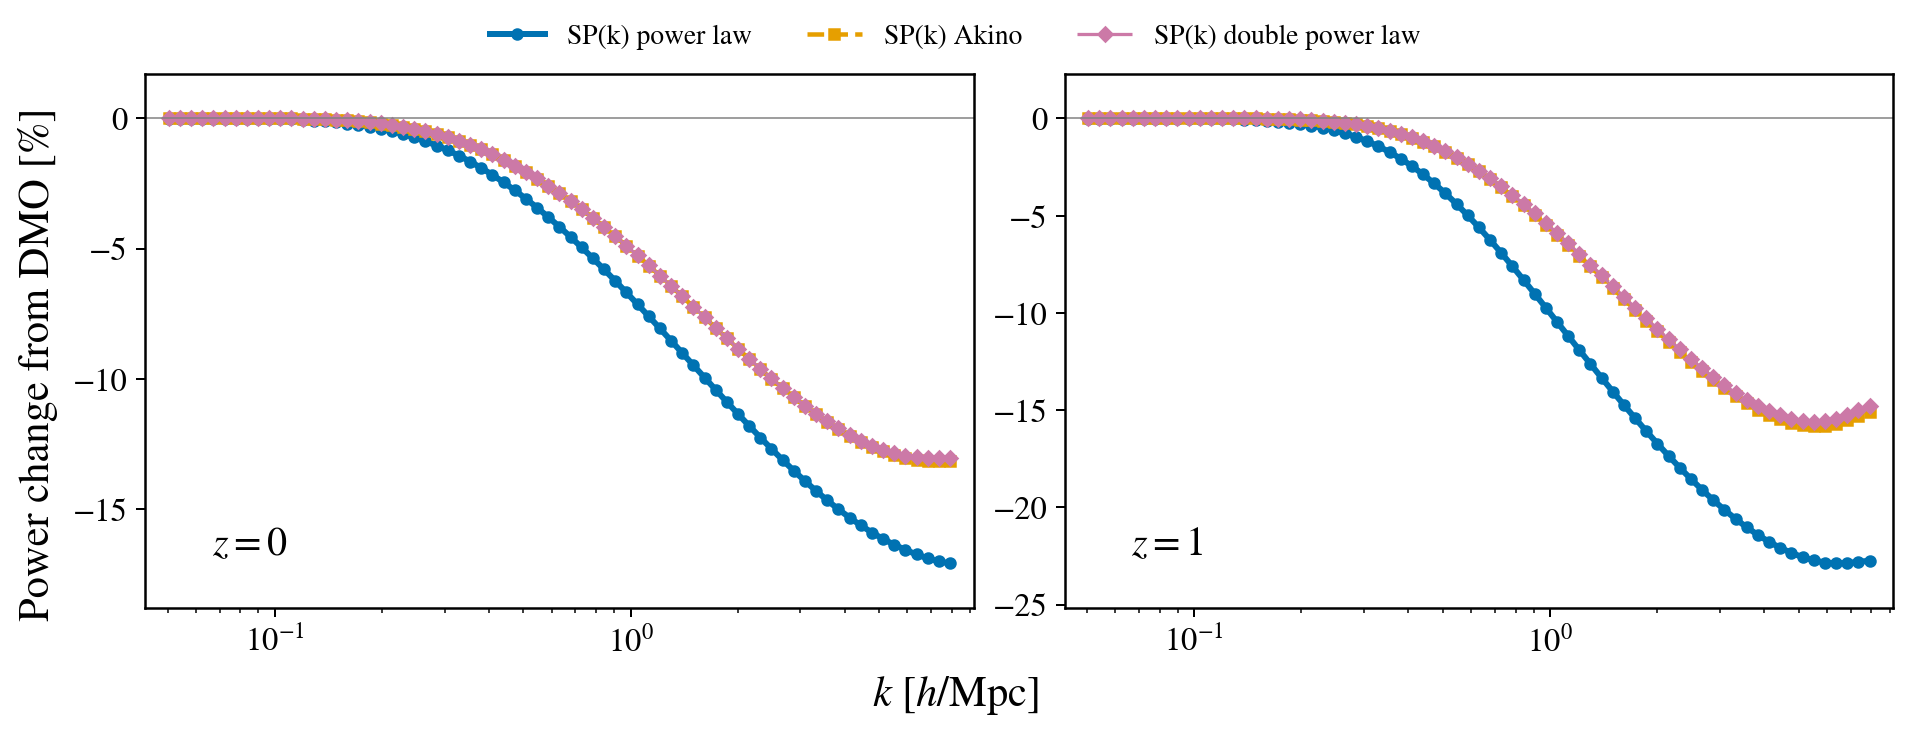

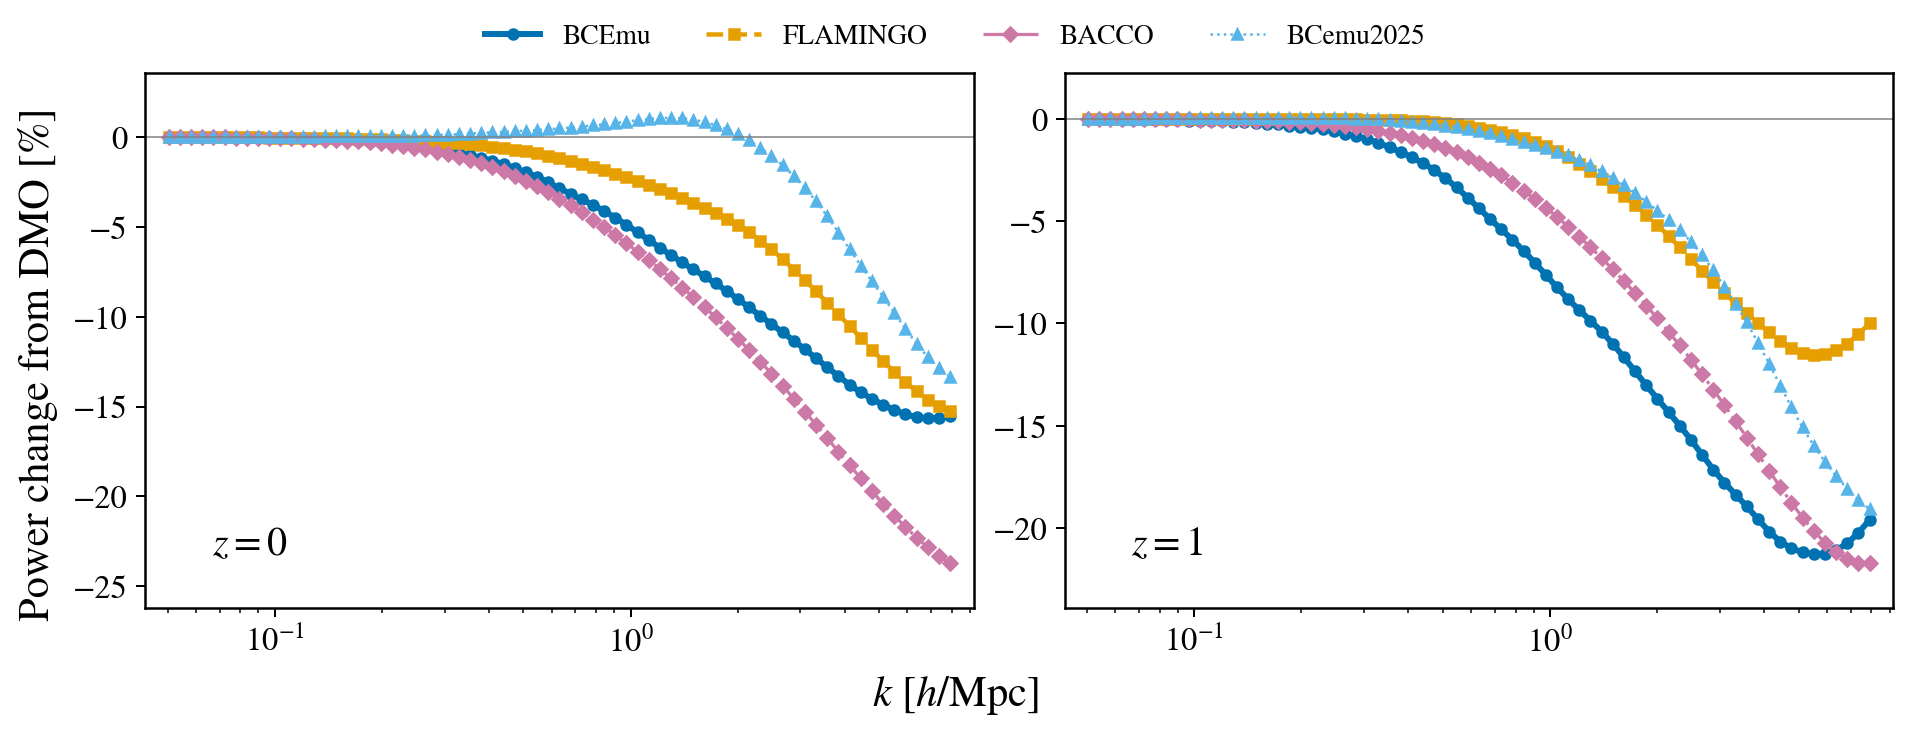

In [5]:
selected_k = (result["k"] >= 0.05) & (result["k"] <= 8.0)
redshift_indices = [int(np.argmin(np.abs(result["z"] - value))) for value in (0., 1.)]
np.testing.assert_allclose(result["z"][redshift_indices], [0., 1.], atol=1.e-12)
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = result["responses"][index, redshift_indices][:, selected_k]
        curves.append((result["k"][selected_k], 100. * (values - 1.)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$z=0$", r"$z=1$"],
        coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
        quantity_label="Power change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"power_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"power_{group}.pdf", pad_inches=0.2)
    plt.show()


## 3. Propagate them into the two-point observables

The likelihood multiplies the nonlinear matter table by $R_P(k,z)$ before the
ordinary CosmoLike projection. The figures show source-bin pair (1,1);
the calculation covers all 400 rows. $\xi_+$ and $\xi_-$ respond differently
because they weight the angular power differently: in the small-angle limit,
$\xi_+(\theta)=\int d\ell\,\ell(C_E+C_B)J_0(\ell\theta)/(2\pi)$ and
$\xi_-(\theta)=\int d\ell\,\ell(C_E-C_B)J_4(\ell\theta)/(2\pi)$, where
$C_E,C_B$ are the two shear-parity power spectra and $J_0,J_4$ are Bessel
functions with different oscillatory weights. The same small-scale power
change can therefore produce different angular responses. A fixed-cosmology
change is not a parameter constraint: a fit must also vary cosmology and
nuisance parameters, apply the intended cuts, and use their covariance.

For BACCO, $R_P$ describes cold matter, meaning cold dark matter (CDM) plus
baryons. The existing Cocoa two-point prescription applies this ratio to the
total nonlinear power, which also contains the massive neutrinos of this DES
point ($\sum m_\nu=0.06\,\mathrm{eV}$). The notebook keeps that prescription
and labels it an approximation; displaying these curves does not establish its
validity. The six power-only models get no manufactured Map3 curve.

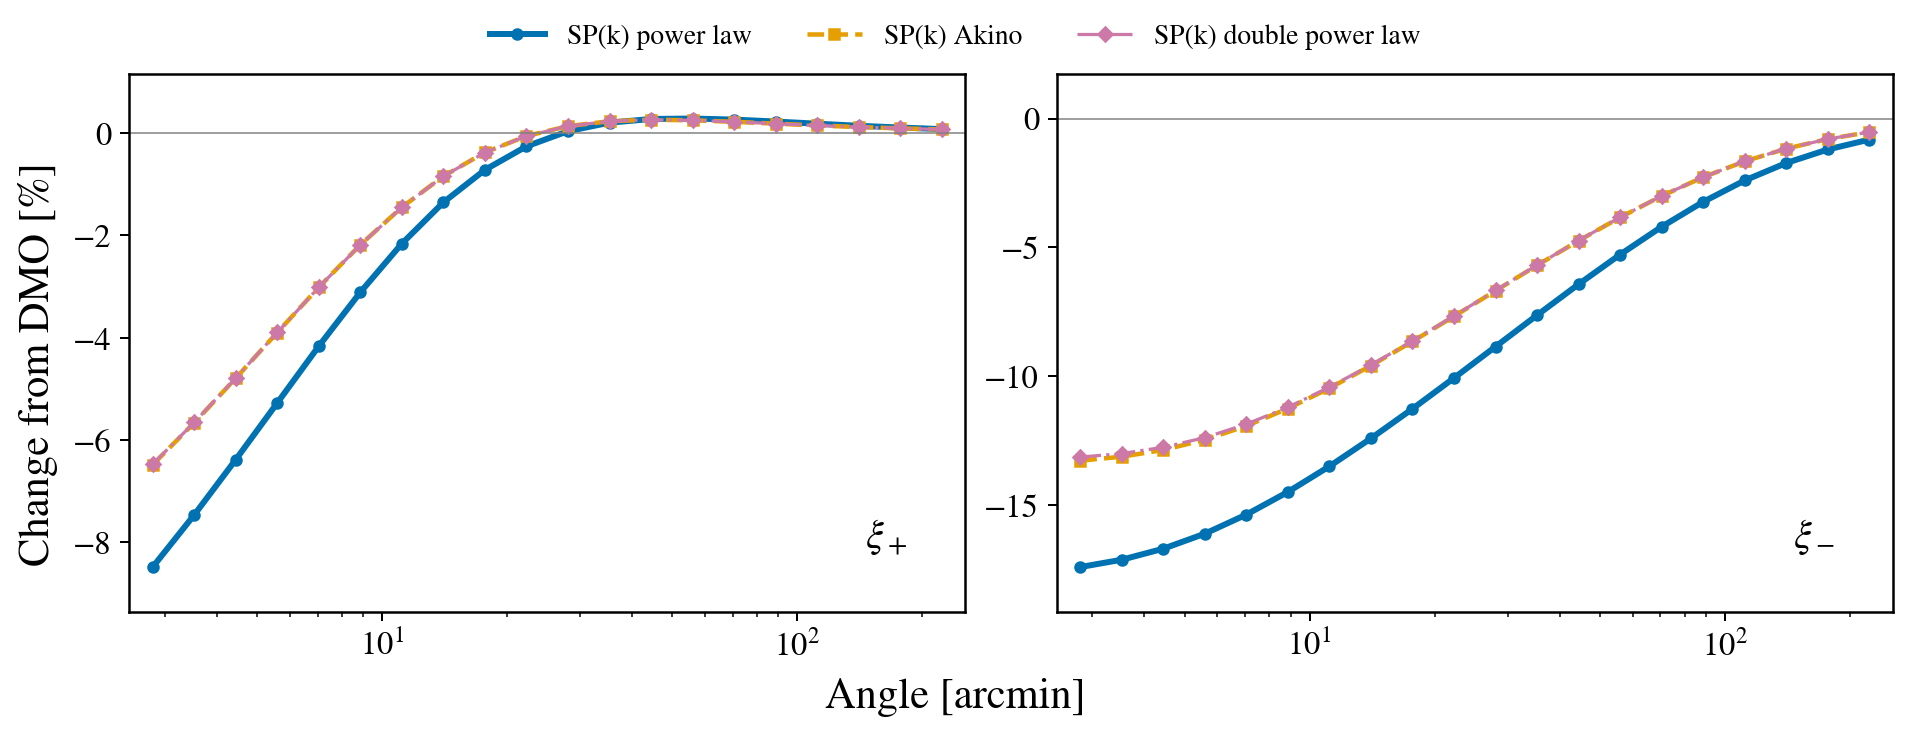

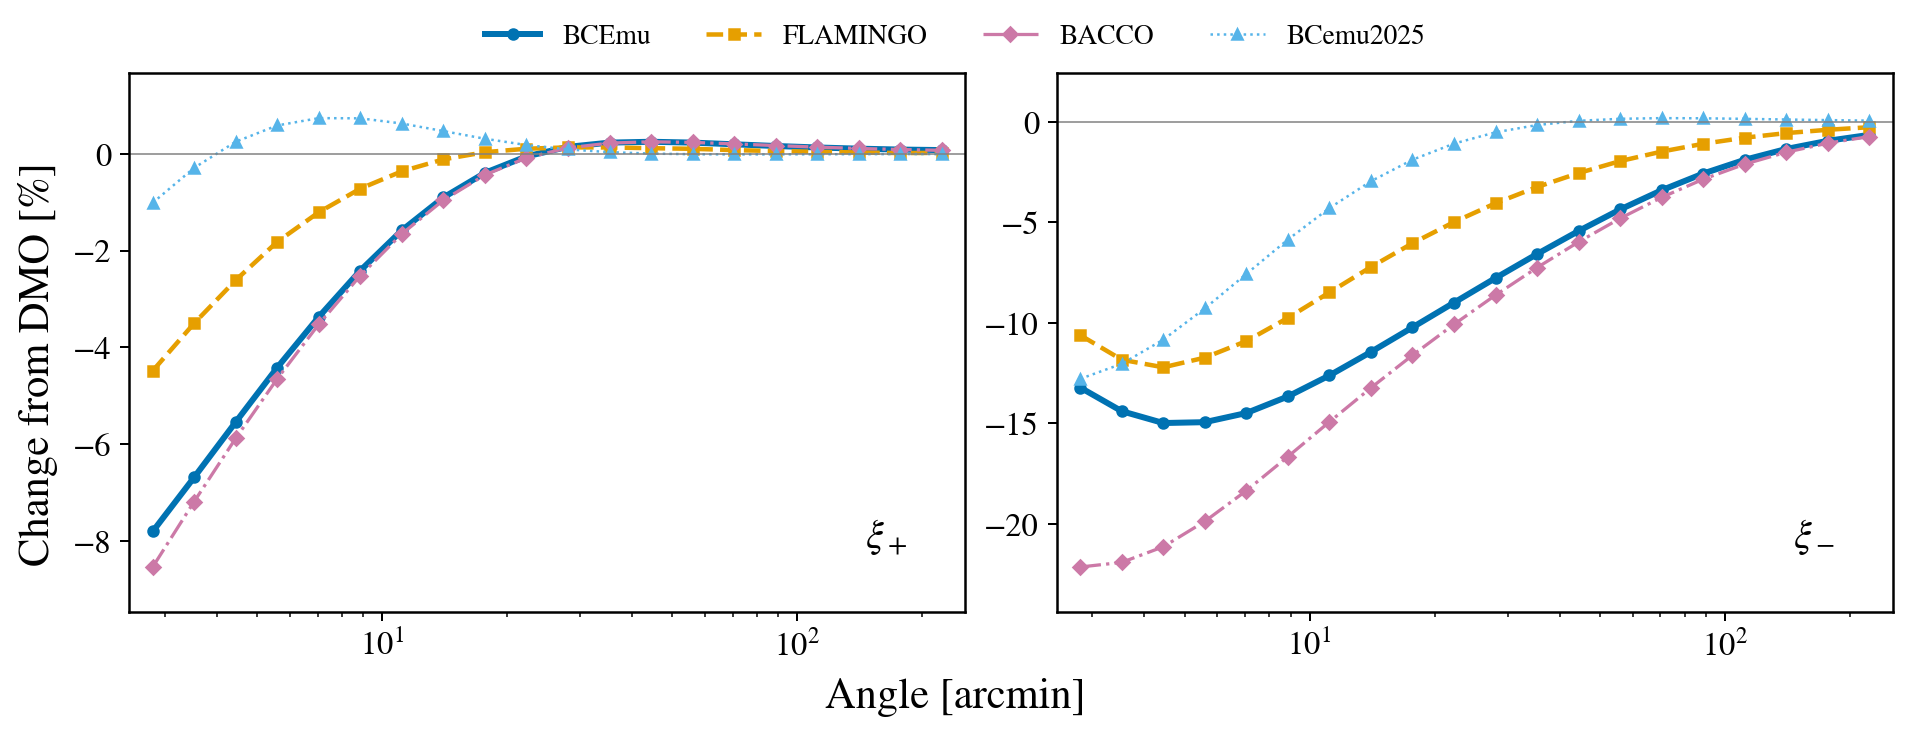

In [6]:
rows = result["rows"]
selected_rows = []
for kind in ("xip", "xim"):
    selected_rows.append(np.flatnonzero(
        (rows.kind == kind) & (rows.bins[:, 0] == 0) & (rows.bins[:, 1] == 0)
    ))
angles = rows.angles[selected_rows[0], 2] * 180. * 60. / np.pi
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = []
        for chosen in selected_rows:
            values.append(100. * (
                result["means"][index, chosen] / result["reference"][chosen] - 1.
            ))
        curves.append((angles, np.asarray(values)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
        coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"xi_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"xi_{group}.pdf", pad_inches=0.2)
    plt.show()


## 4. Evaluate the installed paired BACCO models

Burger et al. (arXiv:2506.18974) train a power response and a separate
bispectrum response from the same baryonic correction model, and the installed
BACCO package contains both, although bfmt exposes only power. The next cell
uses identical cold-matter cosmology and five feedback parameters for the
pair, and it obtains $\sigma_{8,cb}$ from the same BACCO amplitude conversion
bfmt uses rather than substituting the total-matter $\sigma_8$.

The baryonic correction model (BCM) moves matter around halos with five shared
parameters. All API inputs below are base-ten logarithms, even when a symbol
names a scale or slope rather than a mass:

| API coordinate | Physical role |
|---|---|
| `M_c` | Halo mass scale governing how much gas a halo keeps |
| `beta` | Mass dependence of the kept gas fraction |
| `eta` | Extent of ejected gas |
| `M1_z0_cen` | Mass scale in the central-galaxy stellar-mass relation |
| `theta_inn` | Inner gas-profile scale |

For example, `eta=-0.3` means an ejection coordinate of $10^{-0.3}$, not a
negative gas mass; the YAML lists the actual parameter numbers.

The triangles are equilateral $(k,k,k)$ and scalene $(0.6k,k,1.2k)$. Every
side stays within the installed side bounds, and highly squeezed and
degenerate triangles stay out on purpose. The adapter refuses out-of-range
inputs, checks the returned triangle order and counts, and records the
weight-file hashes, so an upstream float32 conversion or row removal cannot
silently change which triangles the curves represent. Staying inside the side
bounds is not an accuracy certificate for every triangle shape.

$R_B$ cannot in general follow from $R_P$, and the curves below impose no
$R_B=R_P^2$ or other power law: they demonstrate the available input. Both
responses describe cold matter rather than the full matter field when
neutrinos are massive, so a calibrated joint-lensing forecast still needs the
matter conversion or a documented approximation, a tested continuation outside
the training domain, and fresh responses whenever cosmology or feedback
parameters change. None of this requires the large covariance simulation
suite.

Sources: [Burger et al., arXiv:2506.18974](https://arxiv.org/abs/2506.18974),
[BACCO documentation](https://baccoemu.readthedocs.io/en/latest/).

The next cell defines `bacco_diagnostic`, the only function of this section:
it loads the two installed response emulators at the recorded BACCO
coordinates of the scenario run and evaluates them on the two triangle
families. The cell after it plots the curves, and section 5's
`save_scenarios` stores them.

In [7]:
# Functions of this notebook: the paired BACCO check of section 4.
import numpy as np


def bacco_diagnostic(records):
    """Evaluate the installed paired models on two supported triangle families.

    The check of section 4: the installed BACCO package (Burger et al.,
    arXiv:2506.18974) carries a power response and a separate bispectrum
    response trained from the same baryonic correction model, and this
    function evaluates both at the cold-matter coordinates run_scenarios
    recorded for its BACCO scenario, so the pair is shown at exactly the
    cosmology and feedback point that scenario used. The next cell plots
    the curves, and save_scenarios stores them in the notebook's NPZ.

    Arguments:
      records = the per-scenario records of run_scenarios; the entry
        named BACCO must carry the bacco_coordinates diagnostic.
    Returns:
      dictionary with k[80] (the sampled sides in h/Mpc), power[2,80],
      bispectrum[2,2,80] and a JSON-compatible provenance record. Axis
      meanings are redshift [0,1], triangle family [equilateral,
      scalene], k; scalene sides are [0.6k,k,1.2k]. Every side stays
      inside the side-length range the emulator weights were trained on.
    Raises:
      StopIteration when the records contain no BACCO entry.
    Side effects:
      Loads two already-installed small emulators. No physical projection.
    """
    from theory.bacco_bispectrum.emulator import BaccoColdResponses

    # next(...) takes the first record whose name is BACCO from the
    # generator expression; with no such record the generator is exhausted
    # and next raises StopIteration.
    record = next(item for item in records if item["name"] == "BACCO")
    emulator = BaccoColdResponses(coordinates=record["bacco_coordinates"])

    # The side range 0.03--6 stays away from calibration boundaries for
    # both shapes; the 80 sampled sides run over 0.05--5 h/Mpc. Squeezed
    # and degenerate triangles are avoided in this example.
    wave = np.geomspace(0.05, 5.0, 80)
    power = []
    bispectrum = []
    for redshift in (0.0, 1.0):
        shapes = []
        for ratios in ((1.0, 1.0, 1.0), (0.6, 1.0, 1.2)):
            sides = wave[:, None] * np.asarray(ratios)[None, :]
            response_p, response_b = emulator.evaluate(z=redshift, k=wave, sides=sides)
            shapes.append(response_b)
        power.append(response_p)
        bispectrum.append(shapes)

    return {
        "k": wave,
        "power": np.asarray(power),
        "bispectrum": np.asarray(bispectrum),
        "record": {
            "coordinates": record["bacco_coordinates"],
            "sigma8_source": record["bacco_sigma8_source"],
            "weights": emulator.weights,
            "matter_field": "CDM+baryons",
            "redshifts": [0.0, 1.0],
            "shapes": [[1.0, 1.0, 1.0], [0.6, 1.0, 1.2]],
        },
    }

Shared cold-matter coordinates: {'omega_cold': 0.28777721867714046, 'omega_baryon': 0.0463, 'sigma8_cold': 0.7898237705230713, 'M_c': 14.0, 'eta': -0.3, 'beta': -0.22, 'M1_z0_cen': 10.5, 'theta_inn': -0.86}


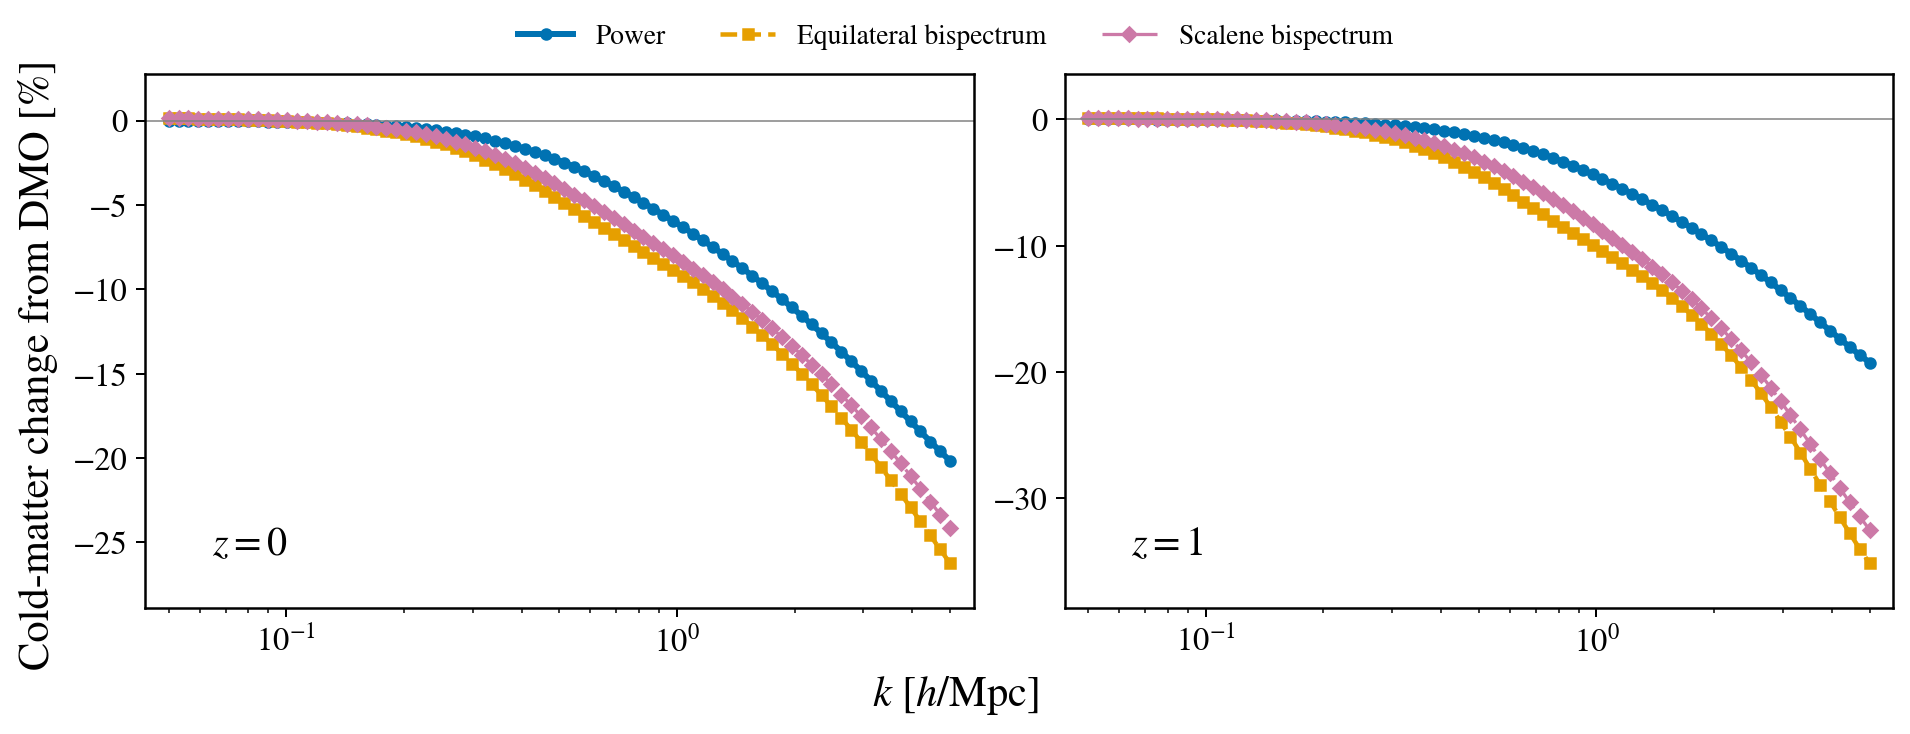

In [8]:
paired = bacco_diagnostic(records=result["records"])
print("Shared cold-matter coordinates:", paired["record"]["coordinates"])
curves = [(paired["k"], 100. * (paired["power"] - 1.))]
for shape in range(2):
    curves.append((paired["k"], 100. * (paired["bispectrum"][:, shape] - 1.)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$z=0$", r"$z=1$"],
    coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
    quantity_label="Cold-matter change from DMO [%]",
    legend=["Power", "Equilateral bispectrum", "Scalene bispectrum"],
    marker=["o", "s", "D"], linewidth=[2.4, 1.8, 1.3],
    linestyle=["-", "--", "-."], ncols=2, figsize=(10.5, 4.0),
    legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "bacco_paired.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "bacco_paired.pdf", pad_inches=0.2)
plt.show()


## 5. Check extrapolation and save the numerical evidence

The run keeps the original bfmt output at every requested wavenumber. For one
diagnostic only, it replaces FLAMINGO's continuation above
$10\,h/\mathrm{Mpc}$ by the value at that pivot and recalculates the two-point
vector; the figure compares the two choices. A difference identifies
sensitivity to the assumed small-scale power, and holding the boundary
constant is itself an assumption, not a calibrated extension.

The NPZ records all 400 rows, all seven response tables, the paired BACCO
curves, the model points, the theory and weight hashes, and the exact DMO
restoration; its local numerical checks are not a survey-accuracy
certification. [EXAMPLE_JOINT_FEEDBACK](EXAMPLE_JOINT_FEEDBACK.ipynb)
applies the paired BACCO response to the joint $\xi_\pm$ and Map3 rows, while
this notebook provides the power-only scenarios.

The next cell defines `save_scenarios`, which writes the plotted arrays and
their records to one NPZ under `chains/`; the final cell draws the tail-test
figure and then runs it.

In [9]:
# Functions of this notebook: save the arrays this notebook plots (section 5).
import json
from pathlib import Path

import numpy as np


def save_scenarios(result, paired, destination):
    """Save the notebook's plotted arrays and input evidence without pickle.

    The final cell calls this after the figures are drawn, so the NPZ
    under chains/ holds exactly what the notebook showed: all xi rows,
    every response table, the paired BACCO curves and the provenance
    records of the run. Reading it back needs no pickle and no project
    code.

    Arguments:
      result, paired = outputs of run_scenarios and bacco_diagnostic.
      destination = notebook-owned NPZ under chains/; reruns replace this output.
    Returns:
      resolved output path. Source inputs and emulator weights are untouched.
    Side effects:
      Creates the destination directory when needed and writes the npz
      file (an existing file at the destination is replaced).
    """
    destination = Path(destination).resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)

    # One JSON metadata string carries every record, so the npz holds only
    # plain arrays and loads with allow_pickle=False.
    record = dict(result["record"], scenarios=result["records"], paired=paired["record"])
    arrays = dict(
        k=result["k"],
        z=result["z"],
        responses=result["responses"],
        reference=result["reference"],
        means=result["means"],
        labels=result["rows"].labels,
        paired_k=paired["k"],
        paired_power=paired["power"],
        paired_bispectrum=paired["bispectrum"],
        metadata=np.asarray(json.dumps(record, sort_keys=True)),
    )
    if result["tail_test"] is not None:
        arrays["tail_test"] = result["tail_test"]
    np.savez_compressed(destination, **arrays)
    return destination

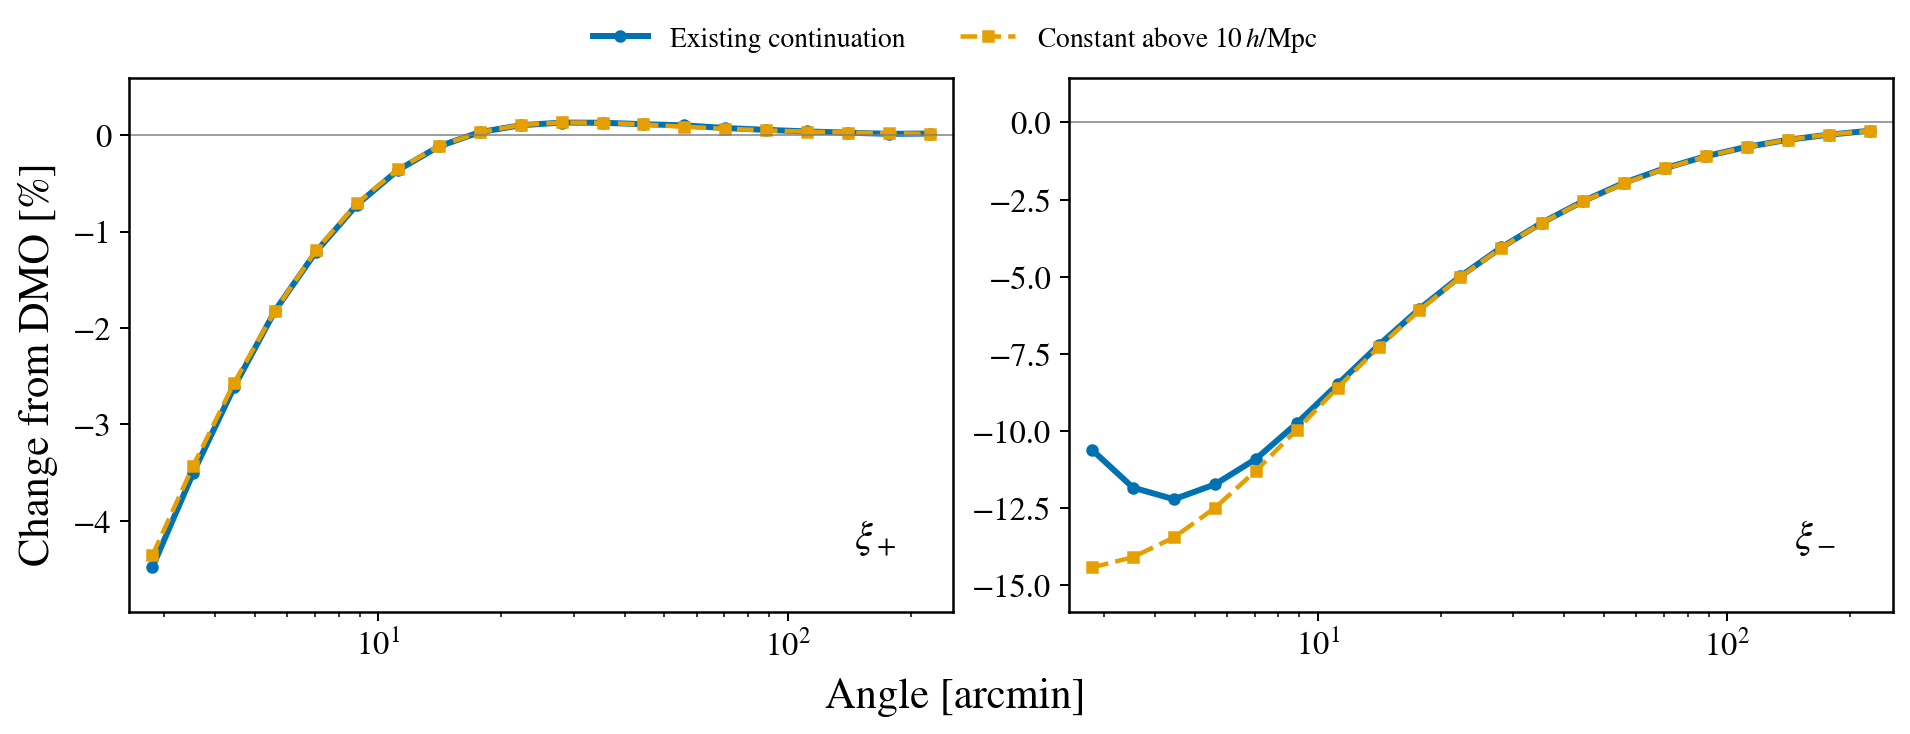

/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/chains/feedback_scenarios.npz


In [10]:
curves = []
flamingo = result["names"].index("FLAMINGO")
for mean in (result["means"][flamingo], result["tail_test"]):
    values = []
    for chosen in selected_rows:
        values.append(100. * (mean[chosen] / result["reference"][chosen] - 1.))
    curves.append((angles, np.asarray(values)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
    coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
    legend=["Existing continuation", r"Constant above $10\,h/\mathrm{Mpc}$"],
    marker=["o", "s"], linewidth=[2.4, 1.8], linestyle=["-", "--"],
    ncols=2, figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "flamingo_tail.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "flamingo_tail.pdf", pad_inches=0.2)
plt.show()
print(save_scenarios(
    result=result, paired=paired, destination=PROJECT / "chains/feedback_scenarios.npz",
))
